In [1]:
import random
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

#data_path = 'data/abc_tls_data/'
data_path = 'data/abc_non_lin_om_data/'
arr = pd.read_csv(data_path+"Delta_1.csv", header=None).to_numpy()[:, :-1] # remove last column as it is empty
arr = arr.astype('float32')

print(f"Shape of data: {arr.shape}")
print(f"Number of photons detected in trajectory: {arr.shape[0]}")
print(f"Number of trajectories per unique detuning value (label): {arr.shape[1]}")
print("There are 100 unique detuning values (labels) in the dataset, ranging from 0.1 to 10.0 in increments of 0.1. See README.txt in dataset for more details.")

Shape of data: (80, 4000)
Number of photons detected in trajectory: 80
Number of trajectories per unique detuning value (label): 4000
There are 100 unique detuning values (labels) in the dataset, ranging from 0.1 to 10.0 in increments of 0.1. See README.txt in dataset for more details.


In [2]:
abc_dataset_X = []
abc_dataset_y = []

# loop through all 100 detuning values
for i in range(1, 101):
    
    trajectories = pd.read_csv(data_path + f"Delta_{i}.csv", header=None).to_numpy()[:, :-1].astype('float32')
    # From README.txt of dataset: The true value of the detuning is the numerical label/10
    true_detuning = i/10.0
    # need to have tuples of (trajectory, true_detuning) not (batches of trajectories, true_detuning) for ABC
    #print(trajectories.shape)
    # create datasets for ML model training
    # flatten each trajectory to be a 1D array of photon counts across time bins
    for trajectory in trajectories.T: # take the transpose to loop through trajectories instead of time bins (data originally came in a format where the hold are the photon detection time delays)
        abc_dataset_X.append(trajectory) 
        abc_dataset_y.append(true_detuning)

In [3]:
abs_dataset_X = np.asarray(abc_dataset_X)
abs_dataset_y = np.asarray(abc_dataset_y)

print(f"Shape of ABC dataset X: {abs_dataset_X.shape}")
print(f"Shape of ABC dataset y: {abs_dataset_y.shape}")
X_train, X_test, y_train, y_test = train_test_split(abc_dataset_X, abc_dataset_y, test_size=0.20, random_state=42, stratify=abc_dataset_y)
X_train, X_test, y_train, y_test = np.asarray(X_train), np.asarray(X_test), np.asarray(y_train), np.asarray(y_test)
print(f"Size of training datasets: X: {X_train.shape}, y: {y_train.shape}")
print(f"Size of test datasets: X: {X_test.shape}, y: {y_test.shape}")



Shape of ABC dataset X: (400000, 80)
Shape of ABC dataset y: (400000,)
Size of training datasets: X: (320000, 80), y: (320000,)
Size of test datasets: X: (80000, 80), y: (80000,)


In [4]:
dataset_type = data_path.split("/")[1]

os.makedirs(f"data/{dataset_type}/train", exist_ok=True)
os.makedirs(f"data/{dataset_type}/test", exist_ok=True)

np.save(f"data/{dataset_type}/train/taus", X_train)
np.save(f"data/{dataset_type}/train/deltas", y_train)
np.save(f"data/{dataset_type}/test/taus", X_test)
np.save(f"data/{dataset_type}/test/deltas", y_test)

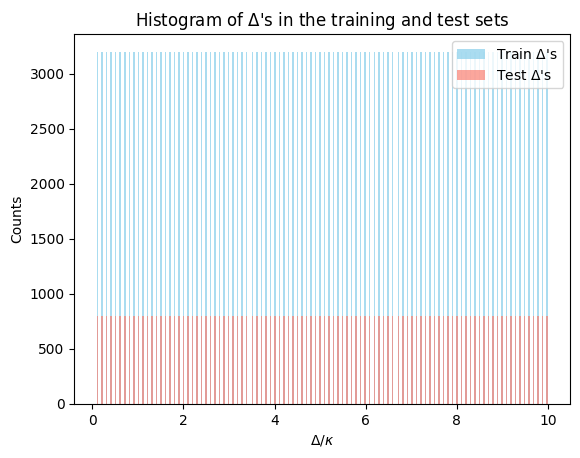

In [5]:
data = [y_train.flatten(), y_test.flatten()]
plt.hist(data[0], bins=300, alpha=0.7, label=fr"Train $\Delta$'s", color="skyblue")
plt.hist(data[1], bins=300, alpha=0.7, label=fr"Test $\Delta$'s", color="salmon")
plt.xlabel(r"$\Delta/\kappa$")
plt.ylabel("Counts")
plt.legend()
plt.title(r"Histogram of $\Delta$'s in the training and test sets");

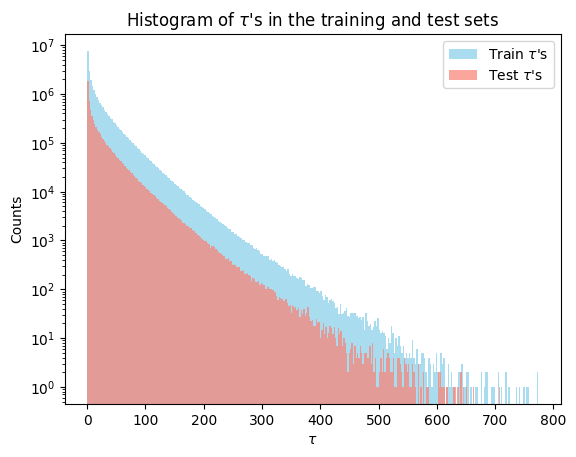

In [6]:
data = [X_train.flatten(), X_test.flatten()]
plt.hist(data[0], bins=300, alpha=0.7, label=rf"Train $\tau$'s", color="skyblue")
plt.hist(data[1], bins=300, alpha=0.7, label=rf"Test $\tau$'s", color="salmon")
plt.xlabel(r"$\tau$")
plt.ylabel("Counts")
plt.yscale("log")
# plt.xscale("log")
plt.legend()
plt.title(r"Histogram of $\tau$'s in the training and test sets");